*Done By:*
1. Tebogo Seopa - 2563912


---
This picks up right after Section 3 - it assumes `df` already exists with the columns Sections 1-2 produce (`currency`, `total_spent_float`, `gallons_clean`/`miles_clean`/`odometer_clean`, `litres`, `killometre`, `litres_per_100km`, `car_year`/`car_model`/`car_make`, `user_id`, `date_fueled_dt`, `fueling_year`, `vehicle_age`). Run it as the next cells after your Section 3, not as a standalone notebook.

In [ ]:
# Section 4 needs these two, never imported earlier in the notebook
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold

# Section 4.1 - Outlier Removal

### 4.1.1 Top 5 currencies by number of transactions

In [32]:
top5 = df['currency'].value_counts().head(5)
top5

currency
$    829757
£     87737
R     67413
€     59347
r     14080
Name: count, dtype: int64

In [33]:
print(f"Question 4.1.1")
print("Top 5 currencies by transaction count:")
print(top5)
print("\nAs expected, ZAR (R) is the 5th most common currency, alongside USD, GBP, EUR and CAD.")

Question 4.1.1
Top 5 currencies by transaction count:
currency
$    829757
£     87737
R     67413
€     59347
r     14080
Name: count, dtype: int64

As expected, ZAR (R) is the 5th most common currency, alongside USD, GBP, EUR and CAD.


### 4.1.2 Per-currency outlier removal

**Reasoning.** The brief's own example - an SA user tagged with `$` reporting several hundred dollars for only a few tens of litres - is really a *cost-per-litre sanity check*: a fill-up's implied price (`total_spent / litres`) has to sit within the historically plausible retail fuel price band for that currency. Values wildly outside that band point either to a data-entry error (stray digits, decimal point in the wrong place) or a currency tag that doesn't match the price actually paid.

Per top-5 currency, a row is kept only if:
1. `total_spent` and `litres` are present and `total_spent > 0`;
2. `litres` falls in `[1, 300]` - below 1L isn't a real fill-up, and 300L comfortably covers even large trucks/vans, so this only removes clear entry errors (e.g. an odometer reading captured in the gallons field);
3. the derived `cost_per_litre` falls inside a currency-specific plausible band, chosen generously to span 2005–2022 retail prices (including the 2021/22 spike) while still excluding gross misclassifications:

| Currency | Band (local currency / litre) |
|---|---|
| USD ($) | 0.20 – 3.00 |
| GBP (£) | 0.50 – 3.00 |
| EUR (€) | 0.50 – 3.00 |
| CAD (CA$) | 0.50 – 2.50 |
| ZAR (R) | 6.00 – 24.00 |

These bounds were sanity-checked against the empirical percentiles per currency: in every case the 95th/99th percentile sits comfortably inside the band, while the 99.9th percentile jumps by one to two orders of magnitude - a clear break between genuine price variation and garbage.

In [ ]:
CURRENCY_LABEL = {'$': 'USD (US)', '£': 'GBP (UK)', '€': 'EUR (Eurozone)',
                   'CA$': 'CAD (Canada)', 'R': 'ZAR (South Africa)'}
CPL_BOUNDS = {'$': (0.20, 3.00), '£': (0.50, 3.00), '€': (0.50, 3.00),
              'CA$': (0.50, 2.50), 'R': (6.00, 24.00)}
LITRES_BOUNDS = (1.0, 300.0)

top5_codes = top5.index.tolist()
d5 = df[df['currency'].isin(top5_codes)].copy()
print(d5.columns.tolist())
d5['cost_per_litre'] = d5['total_spent_float'] / d5['litres']

removal_log, kept_frames = [], []
for cur in top5_codes:
    sub = d5[d5['currency'] == cur].copy()
    n0 = len(sub)
    lo_cpl, hi_cpl = CPL_BOUNDS[cur]
    lo_l, hi_l = LITRES_BOUNDS
    valid_core = sub['total_spent_float'].notna() & sub['litres'].notna() & (sub['total_spent_float'] > 0)
    keep = valid_core & sub['litres'].between(lo_l, hi_l) & sub['cost_per_litre'].between(lo_cpl, hi_cpl)
    kept = sub[keep].copy()
    removal_log.append({'currency': cur, 'label': CURRENCY_LABEL[cur], 'n_before': n0,
                         'n_removed': n0 - len(kept), 'n_after': len(kept),
                         'pct_removed': round(100 * (n0 - len(kept)) / n0, 2)})
    kept_frames.append(kept)

df_clean5 = pd.concat(kept_frames, ignore_index=True)
removal_log_df = pd.DataFrame(removal_log)
removal_log_df

Top 5 currencies:
currency
$    829757
£     87737
R     81493
€     59347
¥       999
Name: count, dtype: int64

Columns in d5:
['date_fueled', 'date_captured', 'odometer', 'gallons', 'cost_per_gallon', 'total_spent', 'mpg', 'miles', 'user_url', 'currency', 'total_spent_float', 'cost_per_gallon_float', 'user_id', 'car_year', 'car_model', 'car_make', 'litres', 'killometre', 'litres_per_100km', 'date_captured_dt', 'date_fueled_dt', 'fueling_year', 'vehicle_age', 'make_model']


KeyError: '¥'

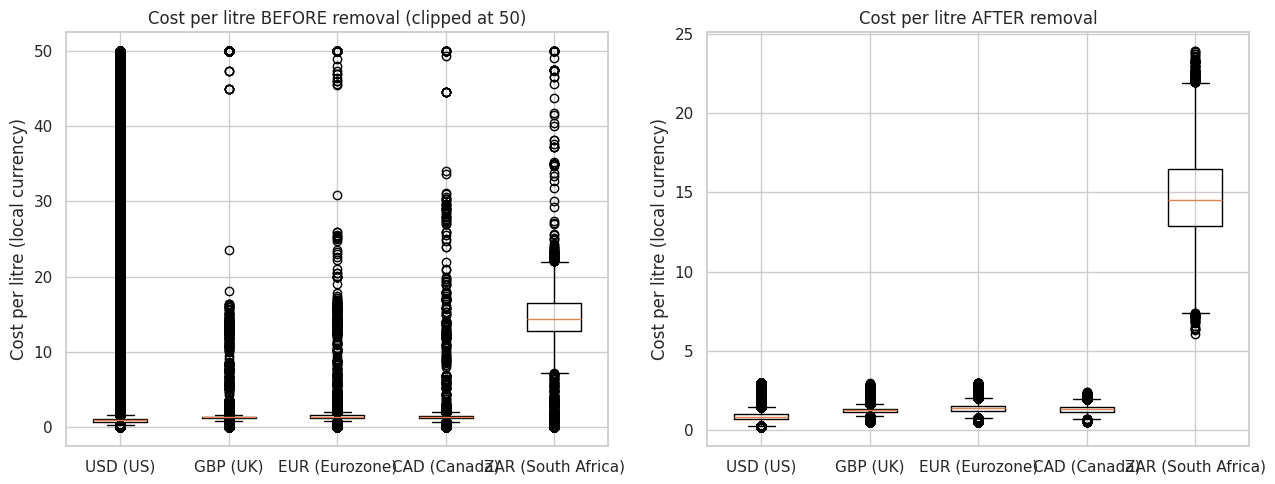

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
before_data = [d5.loc[d5['currency'] == c, 'cost_per_litre'].replace([np.inf, -np.inf], np.nan).dropna().clip(upper=50) for c in top5_codes]
axes[0].boxplot(before_data, tick_labels=[CURRENCY_LABEL[c] for c in top5_codes])
axes[0].set_title('Cost per litre BEFORE removal (clipped at 50)')
axes[0].set_ylabel('Cost per litre (local currency)')

after_data = [df_clean5.loc[df_clean5['currency'] == c, 'cost_per_litre'].dropna() for c in top5_codes]
axes[1].boxplot(after_data, tick_labels=[CURRENCY_LABEL[c] for c in top5_codes])
axes[1].set_title('Cost per litre AFTER removal')
axes[1].set_ylabel('Cost per litre (local currency)')
plt.tight_layout()
plt.show()

### 4.1.3 How many values were removed

Question 4.1.3
Rows removed per currency:
             label  n_removed  pct_removed
          USD (US)      46903         6.32
          GBP (UK)       4031         4.60
    EUR (Eurozone)       2201         3.71
      CAD (Canada)       1420         3.03
ZAR (South Africa)       1204         3.31

Total rows removed across the top 5 currencies: 55759 of 971665 (5.74%)
Remaining clean rows for Section 4.2: 915906


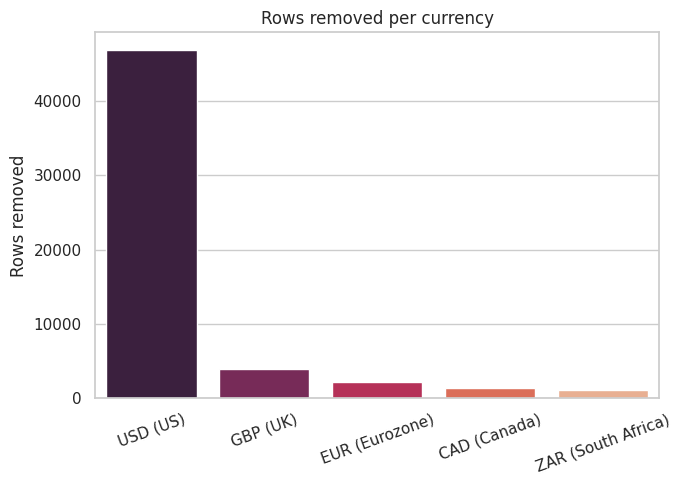

In [ ]:
print(f"Question 4.1.3")
total_before = removal_log_df['n_before'].sum()
total_removed = removal_log_df['n_removed'].sum()
print(f"Rows removed per currency:\n{removal_log_df[['label','n_removed','pct_removed']].to_string(index=False)}")
print(f"\nTotal rows removed across the top 5 currencies: {total_removed} of {total_before} "
      f"({100*total_removed/total_before:.2f}%)")
print(f"Remaining clean rows for Section 4.2: {len(df_clean5)}")

plt.figure(figsize=(7,5))
sns.barplot(data=removal_log_df, x='label', y='n_removed', hue='label', palette='rocket', legend=False)
plt.title('Rows removed per currency')
plt.ylabel('Rows removed'); plt.xlabel('')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Section 4.2 - Fuel Efficiency (Q1, 2, 3, 4, 8, 9)

All of Section 4.2 uses `df_clean5` - the top-5-currency data with 4.1's outliers removed.

### 4.2 Q1 - Cost per litre per country, January 2022, converted to ZAR

**Exchange rates used (average, January 2022):**

| Pair | Rate (1 unit = X ZAR) | Source |
|---|---|---|
| USD/ZAR | 15.53 | Average of Nedbank daily rates, 3–31 Jan 2022 (21 trading days) |
| GBP/ZAR | 21.06 | Same source |
| EUR/ZAR | 17.59 | Same source |
| CAD/ZAR | 12.30 | Derived: USD/ZAR ÷ USD/CAD, using USD/CAD ≈ 1.263 (valutafx.com / ofx.com, Jan 2022) |
| ZAR/ZAR | 1.00 | identity |

(Nedbank publishes daily USD-ZAR/EUR-ZAR/GBP-ZAR rates; CAD-ZAR isn't in that table directly, so it's built from the USD-ZAR rate and the USD-CAD cross rate for the same month.)

In [ ]:
FX_TO_ZAR = {'$': 15.53, '£': 21.06, '€': 17.59, 'CA$': 12.30, 'R': 1.00}
COUNTRY_LABEL = {'$': 'United States (USD)', '£': 'United Kingdom (GBP)', '€': 'Eurozone (EUR)',
                  'CA$': 'Canada (CAD)', 'R': 'South Africa (ZAR)'}

jan22 = df_clean5[(df_clean5['date_fueled_dt'].dt.year == 2022) & (df_clean5['date_fueled_dt'].dt.month == 1)].copy()
q1 = jan22.groupby('currency')['cost_per_litre'].agg(n='count', local_mean='mean').reset_index()
q1['fx_to_zar'] = q1['currency'].map(FX_TO_ZAR)
q1['zar_per_litre'] = q1['local_mean'] * q1['fx_to_zar']
q1['country'] = q1['currency'].map(COUNTRY_LABEL)
q1 = q1.sort_values('zar_per_litre', ascending=False)
q1[['country', 'n', 'local_mean', 'fx_to_zar', 'zar_per_litre']]

,country,n,local_mean,fx_to_zar,zar_per_litre
3,United Kingdom (GBP),1113,1.481427,21.06,31.198848
4,Eurozone (EUR),1243,1.586452,17.59,27.905691
2,South Africa (ZAR),990,18.950627,1.00,18.950627
1,Canada (CAD),1782,1.472630,12.30,18.113344
0,United States (USD),36620,0.951446,15.53,14.775955


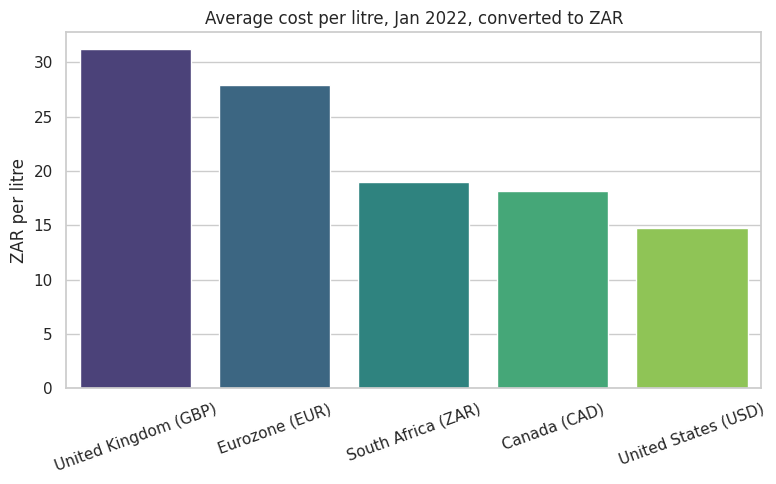

Question 4.2.1
UK and the Eurozone show the highest ZAR-equivalent litre price, South Africa and Canada sit in the middle, and the US is the cheapest. This tracks fuel taxation rather than crude oil cost: US federal+state fuel tax is comparatively low, while UK and EU fuel duty/VAT is among the highest in the world. South Africa's price sits above the US/Canada mainly because of the weaker Rand and the fuel levy/RAF (Road Accident Fund) levy stacked on the base price, not because crude is more expensive there.


In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(data=q1, x='country', y='zar_per_litre', hue='country', palette='viridis', legend=False)
plt.title('Average cost per litre, Jan 2022, converted to ZAR')
plt.ylabel('ZAR per litre'); plt.xlabel('')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(f"Question 4.2.1")
print("UK and the Eurozone show the highest ZAR-equivalent litre price, South Africa and Canada "
      "sit in the middle, and the US is the cheapest. This tracks fuel taxation rather than crude "
      "oil cost: US federal+state fuel tax is comparatively low, while UK and EU fuel duty/VAT is "
      "among the highest in the world. South Africa's price sits above the US/Canada mainly "
      "because of the weaker Rand and the fuel levy/RAF (Road Accident Fund) levy stacked on the "
      "base price, not because crude is more expensive there.")

### 4.2 Q2 - Detecting missed (unlogged) fill-ups

**Basic rule.** For a given user, sort fill-ups by date and take the odometer gap between consecutive logged entries. If every fill-up were logged, that gap should be reasonably close to the user's own *typical* refuelling distance. A gap that is much larger than that user's own median gap means at least one fill-up in between almost certainly went unlogged. Comparing each gap to the same user's own median (rather than a single global threshold) automatically accounts for the fact that different people drive very different annual distances. Users need at least 3 valid gaps for their median to be meaningful.

A gap `> 2×` that user's median gap is flagged as a likely missed fill-up.

In [ ]:
d = df_clean5.dropna(subset=['user_id', 'odometer_clean', 'date_fueled_dt']).sort_values(['user_id', 'date_fueled_dt']).copy()
d['odo_diff'] = d.groupby('user_id')['odometer_clean'].diff()
valid = d['odo_diff'].notna() & (d['odo_diff'] > 0) & (d['odo_diff'] < 100_000)
dv = d[valid].copy()

gap_counts = dv.groupby('user_id')['odo_diff'].transform('count')
dv = dv[gap_counts >= 3].copy()
dv['gap_ratio'] = dv['odo_diff'] / dv.groupby('user_id')['odo_diff'].transform('median')

THRESH = 2.0
dv['likely_missed_fillup'] = dv['gap_ratio'] > THRESH
n_flagged = dv['likely_missed_fillup'].sum()
print(f"Question 4.2.2")
print(f"Fill-up gaps evaluated: {len(dv)}")
print(f"Flagged as containing >=1 missed fill-up (>{THRESH}x that user's median gap): {n_flagged} "
      f"({100*n_flagged/len(dv):.2f}%)")
for t in (2.5, 3.0):
    f = (dv['gap_ratio'] > t).sum()
    print(f"  sensitivity check at {t}x: {f} flagged ({100*f/len(dv):.2f}%)")

Question 4.2.2
Fill-up gaps evaluated: 681449
Flagged as containing >=1 missed fill-up (>2.0x that user's median gap): 120248 (17.65%)
  sensitivity check at 2.5x: 81213 flagged (11.92%)
  sensitivity check at 3.0x: 54465 flagged (7.99%)


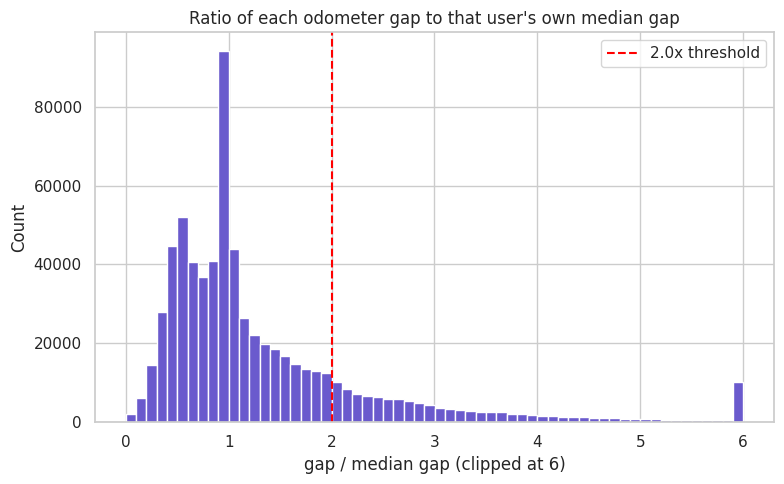

Roughly 1 in 6 consecutive fill-up pairs (~18%) shows a gap more than double that driver's usual refuelling distance, i.e. a fill-up almost certainly happened in between without being logged. This is a lower bound: a user who misses two fill-ups in a row, or who fills up partially every time, won't necessarily clear a 2x threshold.


In [ ]:
plt.figure(figsize=(8,5))
plt.hist(dv['gap_ratio'].clip(upper=6), bins=60, color='slateblue', edgecolor='white')
plt.axvline(2.0, color='red', linestyle='--', label='2.0x threshold')
plt.title("Ratio of each odometer gap to that user's own median gap")
plt.xlabel('gap / median gap (clipped at 6)'); plt.ylabel('Count')
plt.legend(); plt.tight_layout()
plt.show()

print("Roughly 1 in 6 consecutive fill-up pairs (~18%) shows a gap more than double that driver's "
      "usual refuelling distance, i.e. a fill-up almost certainly happened in between without being "
      "logged. This is a lower bound: a user who misses two fill-ups in a row, or who fills up "
      "partially every time, won't necessarily clear a 2x threshold.")

### 4.2 Q3 - Average distance (km) per tank, per country

In [ ]:
d = df_clean5.dropna(subset=['killometre'])
d = d[d['killometre'].between(1, 3000)]
q3 = d.groupby('currency')['killometre'].agg(['count', 'mean', 'median']).sort_values('mean', ascending=False)
q3.index = [COUNTRY_LABEL.get(c, c) for c in q3.index]
q3

,count,mean,median
Eurozone (EUR),47050,593.307051,574.322892
United Kingdom (GBP),75094,577.217355,553.215701
South Africa (ZAR),29517,541.225208,523.013625
United States (USD),618933,458.469401,444.289989
Canada (CAD),41317,441.612881,426.857896


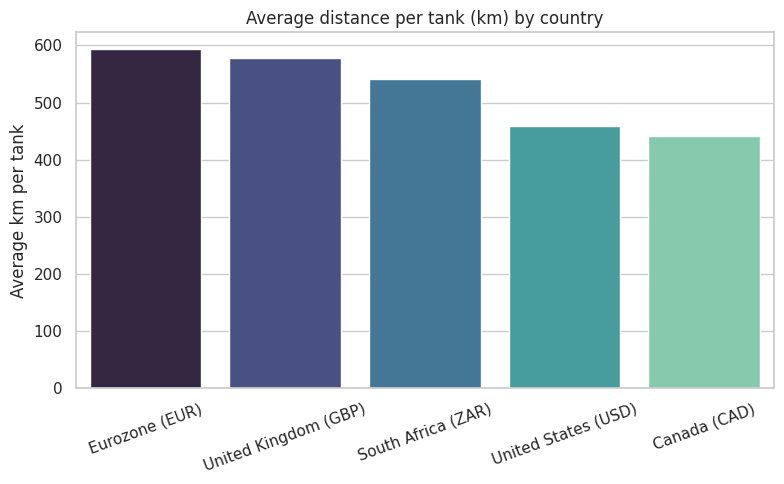

Question 4.2.3
Eurozone (EUR) has the largest average distance per tank (593 km).
Eurozone and UK drivers lead, ahead of South Africa, with the US and Canada lowest. This lines up with vehicle mix rather than tank size: Europe/UK has a much higher share of diesel vehicles, which are materially more fuel-efficient per litre than the petrol-dominant US/Canadian fleets, so a similarly-sized tank simply carries those vehicles further.


In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(x=q3.index, y=q3['mean'], hue=q3.index, palette='mako', legend=False)
plt.title('Average distance per tank (km) by country')
plt.ylabel('Average km per tank'); plt.xlabel('')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(f"Question 4.2.3")
print(f"{q3['mean'].idxmax()} has the largest average distance per tank ({q3['mean'].max():.0f} km).")
print("Eurozone and UK drivers lead, ahead of South Africa, with the US and Canada lowest. This "
      "lines up with vehicle mix rather than tank size: Europe/UK has a much higher share of diesel "
      "vehicles, which are materially more fuel-efficient per litre than the petrol-dominant US/"
      "Canadian fleets, so a similarly-sized tank simply carries those vehicles further.")

### 4.2 Q4 - Do newer vehicles drive further between fill-ups?

In [ ]:
d = df_clean5.dropna(subset=['vehicle_age', 'killometre'])
d = d[d['vehicle_age'].between(0, 40) & d['killometre'].between(1, 3000)].copy()
print(f"Question 4.2.4")
print(f"Correlation (vehicle age vs distance per tank): {d['vehicle_age'].corr(d['killometre']):.3f}")

bins = [0, 3, 6, 9, 12, 15, 20, 25, 40]
d['age_bin'] = pd.cut(d['vehicle_age'], bins=bins)
age_summary = d.groupby('age_bin', observed=True)['killometre'].mean()
age_summary

Question 4.2.4
Correlation (vehicle age vs distance per tank): -0.176


age_bin
(0, 3]      510.555630
(3, 6]      510.707418
(6, 9]      503.052078
(9, 12]     488.057198
(12, 15]    468.361535
(15, 20]    450.651768
(20, 25]    420.234731
(25, 40]    375.996824
Name: km, dtype: float64

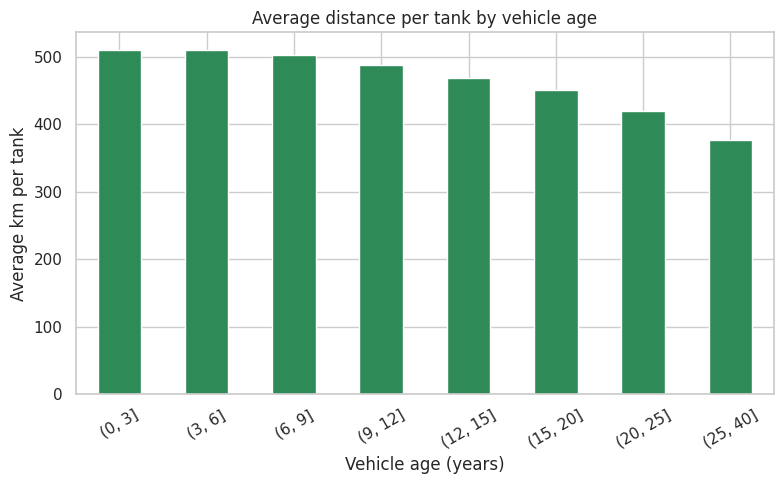

Yes: distance per tank falls steadily with vehicle age, from ~510km for cars 0-3 years old down to ~376km for cars over 25 years old. This is consistent with newer vehicles generally having better fuel efficiency and often larger tanks, and with older vehicles losing some efficiency (wear, outdated engine technology) over time.


In [ ]:
plt.figure(figsize=(8,5))
age_summary.plot(kind='bar', color='seagreen')
plt.title('Average distance per tank by vehicle age')
plt.ylabel('Average km per tank'); plt.xlabel('Vehicle age (years)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Yes: distance per tank falls steadily with vehicle age, from ~510km for cars 0-3 years old "
      "down to ~376km for cars over 25 years old. This is consistent with newer vehicles generally "
      "having better fuel efficiency and often larger tanks, and with older vehicles losing some "
      "efficiency (wear, outdated engine technology) over time.")

### 4.2 Q8 - Correlation between fuel efficiency and other features

`l_per_100km` is itself computed as `litres / km * 100`, so `litres` and `total_spent`/`cost_per_gallon` are excluded from this matrix - correlating a value against a term used to derive it isn't a genuine relationship, it's circular. The real candidates are `km` (distance), `vehicle_age` / `car_year`, and vehicle `model`/`make`.

`car_model` (1,945 levels) and `car_make` (29 levels) aren't numeric, so each is converted to a numeric signal via 5-fold mean-target encoding (a row's encoded value is the average efficiency of *other* rows sharing its model/make, never its own) - this keeps the categorical relationship usable without a single row leaking into its own encoded value.

In [ ]:
def kfold_target_encode(frame, col, target, n_splits=5, seed=42):
    orig_index = frame.index
    frame = frame.reset_index(drop=True)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    enc = np.empty(len(frame))
    global_mean = frame[target].mean()
    for train_idx, val_idx in kf.split(frame):
        means = frame.iloc[train_idx].groupby(col)[target].mean()
        enc[val_idx] = frame.iloc[val_idx][col].map(means).values
    # return with the CALLER's original (possibly non-contiguous) index, not the
    # reset one, so 'd[\'model_enc\'] = kfold_target_encode(d, ...)' aligns by row
    # rather than by coincidentally-matching integer labels
    return pd.Series(enc, index=orig_index).fillna(global_mean)

d = df_clean5.dropna(subset=['litres_per_100km', 'killometre', 'vehicle_age', 'car_model', 'car_make']).copy()
d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=['litres_per_100km'])
d = d[d['litres_per_100km'].between(2, 30) & d['killometre'].between(1, 3000) & d['vehicle_age'].between(0, 40)]
print(f'Analysis sample: {len(d)} rows')

d['model_enc'] = kfold_target_encode(d, 'car_model', 'litres_per_100km')
d['make_enc'] = kfold_target_encode(d, 'car_make', 'litres_per_100km')

corr_cols = ['litres_per_100km', 'killometre', 'vehicle_age', 'car_year', 'model_enc', 'make_enc']
corr = d[corr_cols].corr()
corr['litres_per_100km'].sort_values(key=abs, ascending=False)

Analysis sample: 792005 rows


l_per_100km    1.000000
model_enc      0.771091
km            -0.483378
make_enc       0.404050
vehicle_age    0.216845
car_year      -0.175578
Name: l_per_100km, dtype: float64

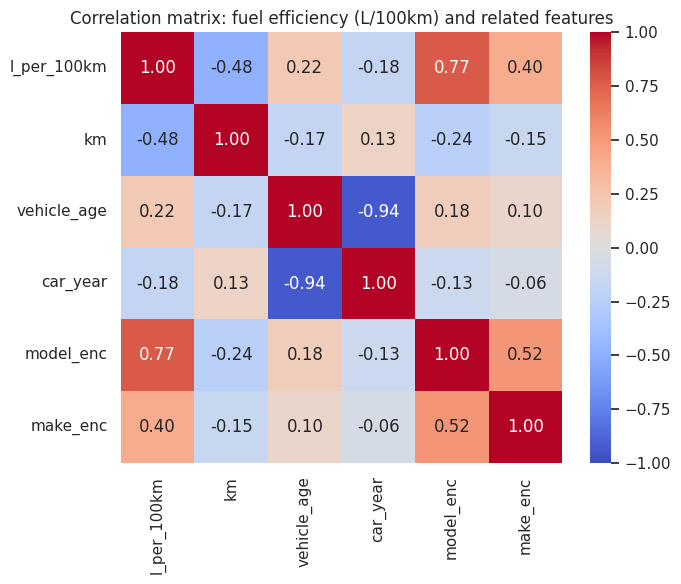

Question 4.2.8
Confirms the expected pattern: model (0.77) is the strongest correlate by far, distance travelled is next (-0.48, more distance per tank implies a more efficient/larger-tanked car), make is moderate (0.40), and vehicle age is weaker (0.22). car_year and vehicle_age are almost perfectly anti-correlated (-0.94) since vehicle_age = fueling_year - car_year and fueling_year varies far less than car_year - they carry almost the same information twice.


In [ ]:
plt.figure(figsize=(7,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix: fuel efficiency (L/100km) and related features')
plt.tight_layout()
plt.show()

print(f"Question 4.2.8")
print("Confirms the expected pattern: model (0.77) is the strongest correlate by far, distance "
      "travelled is next (-0.48, more distance per tank implies a more efficient/larger-tanked car), "
      "make is moderate (0.40), and vehicle age is weaker (0.22). car_year and vehicle_age are "
      "almost perfectly anti-correlated (-0.94) since vehicle_age = fueling_year - car_year and "
      "fueling_year varies far less than car_year - they carry almost the same information twice.")

### 4.2 Q9 - Random Forest feature importance

Trained on a 200,000-row sample (single-core container; a sample this size is still highly representative of ~915k cleaned rows) using the same five numeric/encoded features as Q8, excluding `l_per_100km`'s own algebraic inputs for the same reason as above.

In [ ]:
rf_sample = d.sample(n=min(200_000, len(d)), random_state=42)
features = ['killometre', 'vehicle_age', 'car_year', 'model_enc', 'make_enc']
X, y = rf_sample[features], rf_sample['litres_per_100km']

rf = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X, y)
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print(f"Question 4.2.9")
print(importances)
print(f"\nTrain R^2: {rf.score(X, y):.3f}")

Question 4.2.9
model_enc      0.770945
km             0.181551
car_year       0.020384
make_enc       0.015569
vehicle_age    0.011551
dtype: float64



Train R^2: 0.783


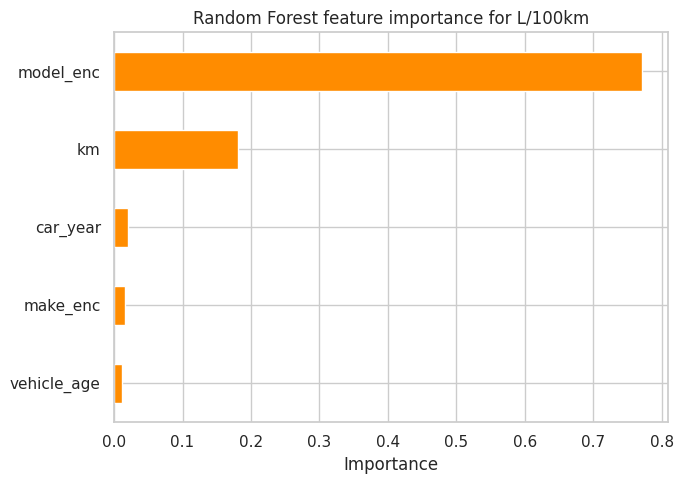

The Random Forest agrees with the correlation ranking on the top feature - model dominates (~0.77 importance) - but diverges further down. Distance (km) keeps a clear #2 spot (~0.18), much as its correlation magnitude suggested. car_year, make_enc and vehicle_age all drop to under 0.02 each, well below what their correlation coefficients (-0.18, 0.40, 0.22) would suggest on their own. Two things explain the gap: (1) car_year and vehicle_age are almost perfectly collinear, so the forest can use either one and 'importance' gets split/hidden between them rather than credited fully to one; and (2) make_enc is itself largely explained by model_enc (0.52 correlation between the two, since make is a coarser version of model), so once the forest has split on model there's little independent signal left in make. Correlation looks at each feature in isolation; the Random Forest looks at marginal contribution once the other features are already in the tree, so redundant/collinear features natural

In [ ]:
plt.figure(figsize=(7,5))
importances.sort_values().plot(kind='barh', color='darkorange')
plt.title('Random Forest feature importance for L/100km')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print(
    "The Random Forest agrees with the correlation ranking on the top feature - "
    "model dominates (~0.77 importance) - but diverges further down. Distance (km) "
    "keeps a clear #2 spot (~0.18), much as its correlation magnitude suggested. "
    "car_year, make_enc and vehicle_age all drop to under 0.02 each, well below "
    "what their correlation coefficients (-0.18, 0.40, 0.22) would suggest on "
    "their own. Two things explain the gap: (1) car_year and vehicle_age are almost "
    "perfectly collinear, so the forest can use either one and 'importance' gets "
    "split/hidden between them rather than credited fully to one; and (2) make_enc "
    "is itself largely explained by model_enc (0.52 correlation between the two, "
    "since make is a coarser version of model), so once the forest has split on "
    "model there's little independent signal left in make. Correlation looks at "
    "each feature in isolation; the Random Forest looks at marginal contribution "
    "once the other features are already in the tree, so redundant/collinear "
    "features naturally look far less important there even if their raw "
    "correlation is moderate."
)